# P-center capacitaire optimisé : comparaison CIR / PIR

Ce notebook traite le clustering de terminaux comme une variante capacitaire et scalable du p-center. On cherche à couvrir tous les terminaux avec des clusters de rayon maximal `45 km`, sous une capacité de débit par cluster `C in {1, 2, 4} Gbps`.

Le notebook compare deux définitions de la demande :

- `CIR` : débit garanti, plus conservateur côté capacité minimale ;
- `PIR` : débit maximal, plus contraignant et utilisé pour dimensionner le pire cas.

L'approche est heuristique : elle construit des clusters valides de manière gloutonne, vérifie les contraintes rayon/débit, puis compare les solutions CIR et PIR.


## 1. Imports et paramètres


In [4]:
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

EARTH_RADIUS_KM = 6371.0088
RAYON_MAX_KM = 45.0
SCENARIOS_DEBIT = [1.0, 2.0, 4.0]
METRICS_TO_RUN = ['CIR', 'PIR']

NB_TERMINAUX_TEST = None  # None = dataset complet
MICROZONE_KM = 10.0
RAYON_RECHERCHE_CANDIDATS_KM = 2.0 * RAYON_MAX_KM
MAX_CANDIDATS_VALIDATION = 80
FUSION_PASSES = 2
FUSION_MAX_VOISINS = 24


EPS = 1e-9
random.seed(42)
np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')

print('Configuration chargee')


Configuration chargee


## 2. Chargement des données et comparaison CIR / PIR


In [5]:
df = pd.read_csv('generated.csv', sep=',')
df = df.dropna(subset=['LON', 'LAT', 'CIR', 'PIR']).copy()
df['CIR_GBPS'] = df['CIR'] / 1000.0
df['PIR_GBPS'] = df['PIR'] / 1000.0

if NB_TERMINAUX_TEST is not None:
    df_run = df.sample(NB_TERMINAUX_TEST, random_state=42).reset_index(drop=True)
else:
    df_run = df.reset_index(drop=True)

rows = []
for metric in METRICS_TO_RUN:
    col = f'{metric}_GBPS'
    rows.append({
        'Demande': metric,
        'Terminaux': len(df_run),
        'Total (Gbps)': round(float(df_run[col].sum()), 2),
        'Moyenne (Mbps)': round(float(df_run[metric].mean()), 2),
        'Max (Gbps)': round(float(df_run[col].max()), 3),
        '> 1 Gbps': int((df_run[col] > 1).sum()),
        '> 2 Gbps': int((df_run[col] > 2).sum()),
        '> 4 Gbps': int((df_run[col] > 4).sum()),
    })

df_demands_summary = pd.DataFrame(rows)
df_demands_summary


,Demande,Terminaux,Total (Gbps),Moyenne (Mbps),Max (Gbps),> 1 Gbps,> 2 Gbps,> 4 Gbps
0,CIR,87989,1068.9,12.15,0.375,0,0,0
1,PIR,87989,12409.5,141.03,1.500,336,0,0


/var/folders/0j/h8dj9z455k33ddx_jll5gvqh0000gn/T/ipykernel_59649/3040694263.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot([df_run['CIR_GBPS'], df_run['PIR_GBPS']], labels=['CIR', 'PIR'], patch_artist=True)


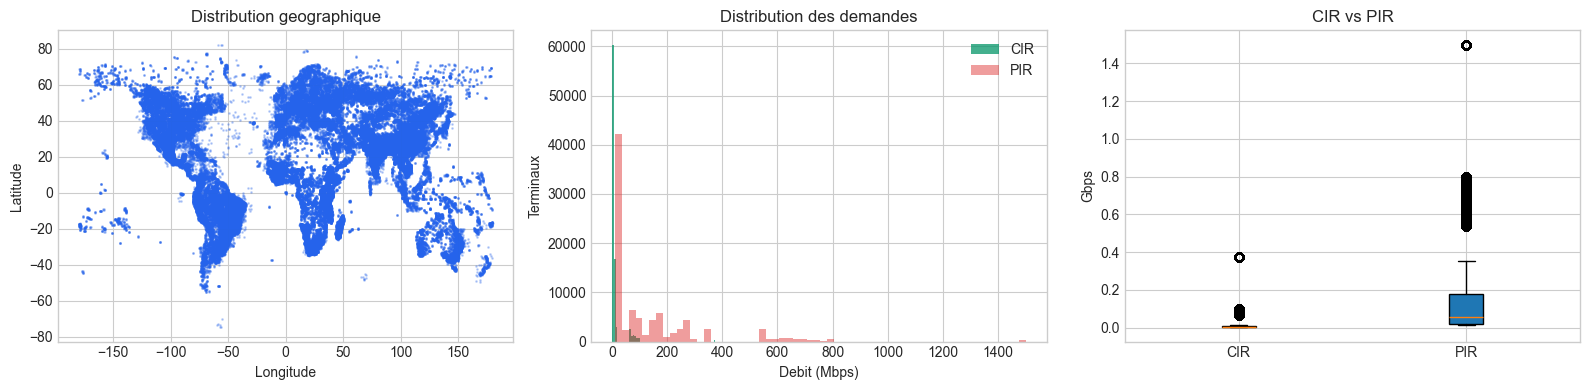

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].scatter(df_run['LON'], df_run['LAT'], s=1, alpha=0.25, color='#2563eb')
axes[0].set_title('Distribution geographique')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')

axes[1].hist(df_run['CIR'], bins=60, color='#059669', alpha=0.75, label='CIR')
axes[1].hist(df_run['PIR'], bins=60, color='#dc2626', alpha=0.45, label='PIR')
axes[1].set_title('Distribution des demandes')
axes[1].set_xlabel('Debit (Mbps)')
axes[1].set_ylabel('Terminaux')
axes[1].legend()

axes[2].boxplot([df_run['CIR_GBPS'], df_run['PIR_GBPS']], labels=['CIR', 'PIR'], patch_artist=True)
axes[2].set_title('CIR vs PIR')
axes[2].set_ylabel('Gbps')

plt.tight_layout()
plt.show()


## 3. Fonctions géographiques


In [7]:
def normaliser_longitude(lon):
    return ((lon + 180.0) % 360.0) - 180.0


def haversine_vectorized(lats, lons, lat_centre, lon_centre):
    lats = np.asarray(lats, dtype=float)
    lons = np.asarray(lons, dtype=float)
    lat1 = np.radians(lats)
    lon1 = np.radians(lons)
    lat2 = math.radians(float(lat_centre))
    lon2 = math.radians(float(lon_centre))
    dlat = lat1 - lat2
    dlon = lon1 - lon2
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * math.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return 2.0 * EARTH_RADIUS_KM * np.arcsin(np.minimum(1.0, np.sqrt(a)))


def latlon_to_unit(lats, lons):
    lat = np.radians(np.asarray(lats, dtype=float))
    lon = np.radians(np.asarray(lons, dtype=float))
    cos_lat = np.cos(lat)
    return np.column_stack((cos_lat * np.cos(lon), cos_lat * np.sin(lon), np.sin(lat)))


def chord_radius(radius_km):
    return 2.0 * math.sin((radius_km / EARTH_RADIUS_KM) / 2.0)


def weighted_center(lats, lons, weights=None):
    lats = np.asarray(lats, dtype=float)
    lons = np.asarray(lons, dtype=float)
    if weights is None:
        weights = np.ones(len(lats))
    weights = np.asarray(weights, dtype=float)
    xyz = latlon_to_unit(lats, lons) * weights[:, None]
    vec = xyz.sum(axis=0)
    norm = np.linalg.norm(vec)
    if norm <= EPS:
        return float(np.average(lats, weights=weights)), float(np.average(lons, weights=weights))
    vec = vec / norm
    lat = math.degrees(math.asin(vec[2]))
    lon = math.degrees(math.atan2(vec[1], vec[0]))
    return float(lat), float(normaliser_longitude(lon))


def project_local(lats, lons, lat0, lon0):
    lat0_rad = math.radians(lat0)
    cos_lat0 = max(abs(math.cos(lat0_rad)), 1e-6)
    delta_lon = ((np.asarray(lons) - lon0 + 180.0) % 360.0) - 180.0
    x = EARTH_RADIUS_KM * np.radians(delta_lon) * cos_lat0
    y = EARTH_RADIUS_KM * np.radians(np.asarray(lats) - lat0)
    return np.column_stack((x, y))


def circle_from_two(a, b):
    center = (a + b) / 2.0
    radius = float(np.linalg.norm(a - center))
    return center, radius


def circle_from_three(a, b, c):
    ax, ay = a
    bx, by = b
    cx, cy = c
    d = 2.0 * (ax * (by - cy) + bx * (cy - ay) + cx * (ay - by))
    if abs(d) < 1e-12:
        candidates = [circle_from_two(a, b), circle_from_two(a, c), circle_from_two(b, c)]
        valid = [circ for circ in candidates if all(np.linalg.norm(p - circ[0]) <= circ[1] + 1e-7 for p in (a, b, c))]
        return min(valid, key=lambda circ: circ[1])
    ux = ((ax * ax + ay * ay) * (by - cy) + (bx * bx + by * by) * (cy - ay) + (cx * cx + cy * cy) * (ay - by)) / d
    uy = ((ax * ax + ay * ay) * (cx - bx) + (bx * bx + by * by) * (ax - cx) + (cx * cx + cy * cy) * (bx - ax)) / d
    center = np.array([ux, uy])
    return center, float(np.linalg.norm(center - a))


def encloses(circle, point):
    center, radius = circle
    return np.linalg.norm(point - center) <= radius + 1e-7


def minimum_enclosing_circle_latlon(lats, lons):
    lats = np.asarray(lats, dtype=float)
    lons = np.asarray(lons, dtype=float)
    if len(lats) == 0:
        return None, 0.0
    if len(lats) == 1:
        return (float(lats[0]), float(lons[0])), 0.0

    lat0, lon0 = weighted_center(lats, lons)
    points = project_local(lats, lons, lat0, lon0)
    order = np.arange(len(points))
    rng = np.random.default_rng(42)
    rng.shuffle(order)
    shuffled = points[order]

    circle = (shuffled[0], 0.0)
    for i, p in enumerate(shuffled):
        if encloses(circle, p):
            continue
        circle = (p, 0.0)
        for j in range(i):
            q = shuffled[j]
            if encloses(circle, q):
                continue
            circle = circle_from_two(p, q)
            for k in range(j):
                r = shuffled[k]
                if not encloses(circle, r):
                    circle = circle_from_three(p, q, r)

    center_xy, _ = circle
    cos_lat0 = max(abs(math.cos(math.radians(lat0))), 1e-6)
    lat_c = lat0 + math.degrees(center_xy[1] / EARTH_RADIUS_KM)
    lon_c = normaliser_longitude(lon0 + math.degrees(center_xy[0] / (EARTH_RADIUS_KM * cos_lat0)))
    real_radius = float(haversine_vectorized(lats, lons, lat_c, lon_c).max())
    return (float(lat_c), float(lon_c)), real_radius


def exact_radius_for_indices(indices, lats, lons, center):
    if len(indices) == 0:
        return 0.0
    return float(haversine_vectorized(lats[indices], lons[indices], center[0], center[1]).max())


def debit_cluster(indices, demands):
    return float(demands[indices].sum()) if len(indices) else 0.0


def cluster_is_valid(indices, center, lats, lons, demands, capacity_gbps):
    return (debit_cluster(indices, demands) <= capacity_gbps + EPS and
            exact_radius_for_indices(indices, lats, lons, center) <= RAYON_MAX_KM + 1e-6)

print('Fonctions geographiques definies')


Fonctions geographiques definies


## 4. Prétraitement : terminaux virtuels, micro-zones et bornes


In [8]:
def prepare_virtual_terminals(df_input, capacity_gbps):
    rows = []
    split_originals = 0
    for original_id, row in df_input.reset_index(drop=True).iterrows():
        demand = float(row.DEMAND_GBPS)
        lat = float(row.LAT)
        lon = float(row.LON)

        if demand <= capacity_gbps + EPS:
            rows.append((len(rows), original_id, lat, lon, demand, 1, 1))
            continue

        split_originals += 1
        full_parts = int(demand // capacity_gbps)
        remainder = demand - full_parts * capacity_gbps
        part_count = full_parts + (1 if remainder > EPS else 0)
        for part in range(full_parts):
            rows.append((len(rows), original_id, lat, lon, capacity_gbps, part + 1, part_count))
        if remainder > EPS:
            rows.append((len(rows), original_id, lat, lon, remainder, part_count, part_count))

    columns = ['virtual_id', 'original_id', 'LAT', 'LON', 'demand_gbps', 'part_no', 'part_count']
    return pd.DataFrame(rows, columns=columns), split_originals


def add_microzones(vdf, cell_km=MICROZONE_KM):
    vdf = vdf.copy()
    cell_deg = cell_km / 111.0
    vdf['zone_lat'] = np.floor((vdf['LAT'] + 90.0) / cell_deg).astype(np.int64)
    vdf['zone_lon'] = np.floor((vdf['LON'] + 180.0) / cell_deg).astype(np.int64)
    zone_keys = pd.MultiIndex.from_arrays([vdf['zone_lat'], vdf['zone_lon']])
    vdf['zone_id'] = pd.factorize(zone_keys)[0]

    zones = []
    for zone_id, group in vdf.groupby('zone_id', sort=False):
        lat_c, lon_c = weighted_center(group['LAT'].to_numpy(), group['LON'].to_numpy(), group['demand_gbps'].to_numpy())
        zones.append({
            'zone_id': int(zone_id),
            'lat': lat_c,
            'lon': lon_c,
            'demand_gbps': float(group['demand_gbps'].sum()),
            'n_virtual': int(len(group)),
            'n_original': int(group['original_id'].nunique()),
        })
    return vdf, pd.DataFrame(zones)


def lower_bounds(total_demand, capacity_gbps, zones):
    debit_lb = int(math.ceil(total_demand / capacity_gbps - EPS))
    if zones.empty:
        return debit_lb, debit_lb

    coords = latlon_to_unit(zones['lat'].to_numpy(), zones['lon'].to_numpy())
    tree = cKDTree(coords)
    available = np.ones(len(zones), dtype=bool)
    zone_demands = zones['demand_gbps'].to_numpy(float)
    zone_counts = zones['n_virtual'].to_numpy(int)
    order = np.lexsort((-zone_counts, -zone_demands))

    geo_lb = 0
    exclusion_radius = chord_radius(2.0 * RAYON_MAX_KM)
    for i in order:
        if not available[i]:
            continue
        geo_lb += int(math.ceil(zone_demands[i] / capacity_gbps - EPS))
        for j in tree.query_ball_point(coords[i], exclusion_radius):
            available[j] = False

    return debit_lb, max(debit_lb, geo_lb)

print('Pretraitement defini')


Pretraitement defini


## 5. Heuristique p-center capacitaire


### 5.1 Recherche large de candidats et remplissage valide


In [9]:
def query_candidates(tree, lats, lons, center, uncovered, radius_km=RAYON_RECHERCHE_CANDIDATS_KM):
    center_xyz = latlon_to_unit([center[0]], [center[1]])[0]
    raw = tree.query_ball_point(center_xyz, chord_radius(radius_km))
    if not raw:
        return np.array([], dtype=np.int64), np.array([], dtype=float)

    indices = np.asarray(raw, dtype=np.int64)
    indices = indices[uncovered[indices]]
    if len(indices) == 0:
        return indices, np.array([], dtype=float)

    distances = haversine_vectorized(lats[indices], lons[indices], center[0], center[1])
    keep = distances <= radius_km + 1e-7
    return indices[keep], distances[keep]


def choose_members(candidate_idx, distances, demands, capacity_gbps, lats, lons,
                   preferred_mask=None, seed_idx=None, max_pool=MAX_CANDIDATS_VALIDATION):
    if len(candidate_idx) == 0:
        return []

    selected = []
    load = 0.0
    remaining = np.ones(len(candidate_idx), dtype=bool)

    if seed_idx is not None:
        hit = np.where(candidate_idx == seed_idx)[0]
        if len(hit) and demands[seed_idx] <= capacity_gbps + EPS:
            pos = int(hit[0])
            selected.append(int(seed_idx))
            load += float(demands[seed_idx])
            remaining[pos] = False

    if preferred_mask is None:
        preferred_mask = np.zeros(len(candidate_idx), dtype=bool)

    while True:
        feasible = remaining & (demands[candidate_idx] <= capacity_gbps - load + EPS)
        if not feasible.any():
            break

        fill_after = (load + demands[candidate_idx]) / capacity_gbps
        slack_after = np.maximum(0.0, 1.0 - fill_after)
        demand_norm = demands[candidate_idx] / capacity_gbps
        dist_norm = distances / RAYON_RECHERCHE_CANDIDATS_KM
        base_score = (0.35 * dist_norm + 0.35 * slack_after - 0.30 * demand_norm - 0.12 * preferred_mask.astype(float))
        base_score[~feasible] = np.inf

        best = None
        checked = 0
        for pos in np.argsort(base_score):
            if not np.isfinite(base_score[pos]):
                break
            test_indices = np.asarray(selected + [int(candidate_idx[pos])], dtype=np.int64)
            _, radius = minimum_enclosing_circle_latlon(lats[test_indices], lons[test_indices])
            checked += 1
            if radius <= RAYON_MAX_KM + 1e-5:
                score = base_score[pos] + 0.45 * (radius / RAYON_MAX_KM)
                if best is None or score < best[0]:
                    best = (score, int(pos))
            if checked >= max_pool:
                break

        if best is None:
            break

        pos = best[1]
        selected.append(int(candidate_idx[pos]))
        load += float(demands[candidate_idx[pos]])
        remaining[pos] = False
        if capacity_gbps - load <= EPS:
            break

    return selected


### 5.2 Centre libre, validation et fusion locale


In [10]:
def cluster_center_and_radius(indices, lats, lons, fallback_center):
    if len(indices) == 0:
        return fallback_center, 0.0
    center, radius = minimum_enclosing_circle_latlon(lats[indices], lons[indices])
    if radius <= RAYON_MAX_KM + 1e-5:
        return center, radius
    fallback_radius = exact_radius_for_indices(indices, lats, lons, fallback_center)
    return fallback_center, fallback_radius


def compact_clusters(clusters, centers):
    new_clusters = []
    new_centers = []
    for cluster, center in zip(clusters, centers):
        if len(cluster):
            new_clusters.append(np.asarray(cluster, dtype=np.int64))
            new_centers.append(center)
    return new_clusters, new_centers


def improve_by_merging(clusters, centers, lats, lons, demands, capacity_gbps,
                       passes=FUSION_PASSES, max_voisins=FUSION_MAX_VOISINS, verbose=False):
    clusters, centers = compact_clusters(clusters, centers)
    nb_initial = len(clusters)
    nb_fusions = 0

    for pass_num in range(passes):
        if len(clusters) <= 1:
            break

        loads = np.array([demands[c].sum() for c in clusters])
        center_xyz = latlon_to_unit([c[0] for c in centers], [c[1] for c in centers])
        tree = cKDTree(center_xyz)
        removed = np.zeros(len(clusters), dtype=bool)
        changed = False

        for i in np.argsort(loads):
            if removed[i] or loads[i] <= EPS:
                continue
            voisins = tree.query_ball_point(center_xyz[i], chord_radius(2.0 * RAYON_MAX_KM))
            voisins = [j for j in voisins if j != i and not removed[j] and loads[i] + loads[j] <= capacity_gbps + EPS]
            voisins.sort(key=lambda j: loads[j], reverse=True)

            for j in voisins[:max_voisins]:
                union = np.concatenate([clusters[i], clusters[j]])
                center, radius = minimum_enclosing_circle_latlon(lats[union], lons[union])
                if radius <= RAYON_MAX_KM + 1e-5:
                    clusters[j] = union
                    centers[j] = center
                    loads[j] += loads[i]
                    clusters[i] = np.array([], dtype=np.int64)
                    loads[i] = 0.0
                    removed[i] = True
                    changed = True
                    nb_fusions += 1
                    break

        clusters, centers = compact_clusters(clusters, centers)
        if not changed:
            break

    if verbose:
        print(f'    Fusion : {nb_initial} -> {len(clusters)} clusters ({nb_fusions} fusions)')
    return clusters, centers


### 5.3 Solveur principal


In [11]:
def capacitated_p_center(df_input, capacity_gbps, metric_name='', verbose=True,
                       max_candidates_validation=MAX_CANDIDATS_VALIDATION):
    start = time.time()
    work_df = df_input.copy().reset_index(drop=True)
    vdf, split_originals = prepare_virtual_terminals(work_df, capacity_gbps)
    vdf, zones = add_microzones(vdf)

    lats = vdf['LAT'].to_numpy(float)
    lons = vdf['LON'].to_numpy(float)
    demands = vdf['demand_gbps'].to_numpy(float)
    zone_ids = vdf['zone_id'].to_numpy(np.int64)
    tree = cKDTree(latlon_to_unit(lats, lons))
    uncovered = np.ones(len(vdf), dtype=bool)
    clusters = []
    centers = []

    total_demand = float(demands.sum())
    borne_debit, borne_geo_approx = lower_bounds(total_demand, capacity_gbps, zones)
    zone_order = zones.sort_values(['demand_gbps', 'n_virtual'], ascending=False)

    if verbose:
        prefix = f'{metric_name} - ' if metric_name else ''
        print(f'{prefix}{capacity_gbps:.0f} Gbps | virtuels={len(vdf)} | zones={len(zones)} | split={split_originals}')

    for rank, zone_row in enumerate(zone_order.itertuples(), start=1):
        local_idx = np.where((zone_ids == zone_row.zone_id) & uncovered)[0]
        if len(local_idx) == 0:
            continue
        local_idx = local_idx[np.argsort(-demands[local_idx])]

        for seed_idx in local_idx:
            if not uncovered[seed_idx]:
                continue
            candidate_idx, distances = query_candidates(
                tree, lats, lons,
                (float(lats[seed_idx]), float(lons[seed_idx])),
                uncovered,
            )
            if len(candidate_idx) == 0:
                continue

            selected = choose_members(
                candidate_idx, distances, demands, capacity_gbps, lats, lons,
                preferred_mask=(zone_ids[candidate_idx] == zone_row.zone_id),
                seed_idx=seed_idx,
                max_pool=max_candidates_validation,
            )
            if not selected:
                continue

            selected = np.asarray(selected, dtype=np.int64)
            center, _ = cluster_center_and_radius(selected, lats, lons, (float(lats[seed_idx]), float(lons[seed_idx])))
            if cluster_is_valid(selected, center, lats, lons, demands, capacity_gbps):
                clusters.append(selected)
                centers.append(center)
                uncovered[selected] = False

        if verbose and rank % 20000 == 0:
            print(f'  zones traitees={rank:>6} | clusters={len(clusters):>6} | restants={int(uncovered.sum()):>6}')

    while uncovered.any():
        available = np.flatnonzero(uncovered)
        seed_idx = int(available[np.argmax(demands[available])])
        candidate_idx, distances = query_candidates(tree, lats, lons, (float(lats[seed_idx]), float(lons[seed_idx])), uncovered)
        selected = choose_members(candidate_idx, distances, demands, capacity_gbps, lats, lons,
                                  seed_idx=seed_idx, max_pool=max_candidates_validation)
        if not selected:
            selected = [seed_idx]
        selected = np.asarray(selected, dtype=np.int64)
        center, _ = cluster_center_and_radius(selected, lats, lons, (float(lats[seed_idx]), float(lons[seed_idx])))
        clusters.append(selected)
        centers.append(center)
        uncovered[selected] = False

    nb_avant_fusion = len(clusters)
    clusters, centers = improve_by_merging(clusters, centers, lats, lons, demands, capacity_gbps, verbose=verbose)

    rayons = np.array([exact_radius_for_indices(cluster, lats, lons, centers[i]) for i, cluster in enumerate(clusters)])
    debits = np.array([demands[cluster].sum() for cluster in clusters])
    tailles = np.array([len(cluster) for cluster in clusters])
    remplissage = 100.0 * debits / capacity_gbps
    nb_invalides = int(((rayons > RAYON_MAX_KM + 1e-6) | (debits > capacity_gbps + EPS)).sum())
    duree = time.time() - start

    if verbose:
        print(f'  clusters={len(clusters)} | invalides={nb_invalides} | temps={duree:.1f}s')

    return {
        'metric': metric_name,
        'capacity_gbps': capacity_gbps,
        'vdf': vdf,
        'zones': zones,
        'clusters': clusters,
        'centers': centers,
        'rayons': rayons,
        'debits': debits,
        'tailles': tailles,
        'remplissage': remplissage,
        'nb_clusters': len(clusters),
        'nb_avant_fusion': nb_avant_fusion,
        'nb_invalides': nb_invalides,
        'split_originals': split_originals,
        'borne_debit': borne_debit,
        'borne_geo_approx': borne_geo_approx,
        'total_demand': total_demand,
        'n_virtual': len(vdf),
        'duree': duree,
        'max_candidates_validation': max_candidates_validation,
    }

print('Solveur capacitaire defini')


Solveur capacitaire defini


## 6. Exécution des scénarios CIR et PIR


In [12]:
resultats = {metric: {} for metric in METRICS_TO_RUN}

for metric in METRICS_TO_RUN:
    print('\n' + '=' * 70)
    print(f'EXECUTION {metric}')
    print('=' * 70)
    df_metric = df_run.copy()
    df_metric['DEMAND_GBPS'] = df_metric[f'{metric}_GBPS']

    for capacity in SCENARIOS_DEBIT:
        print(f'\n--- {metric} | capacite = {capacity:.0f} Gbps ---')
        resultats[metric][capacity] = capacitated_p_center(df_metric, capacity, metric_name=metric, verbose=True)



EXECUTION CIR

--- CIR | capacite = 1 Gbps ---
CIR - 1 Gbps | virtuels=87989 | zones=83621 | split=0
    Fusion : 13413 -> 13413 clusters (0 fusions)
  clusters=13413 | invalides=0 | temps=86.1s

--- CIR | capacite = 2 Gbps ---
CIR - 2 Gbps | virtuels=87989 | zones=83621 | split=0
    Fusion : 13407 -> 13407 clusters (0 fusions)
  clusters=13407 | invalides=0 | temps=89.2s

--- CIR | capacite = 4 Gbps ---
CIR - 4 Gbps | virtuels=87989 | zones=83621 | split=0
    Fusion : 13412 -> 13412 clusters (0 fusions)
  clusters=13412 | invalides=0 | temps=96.3s

EXECUTION PIR

--- PIR | capacite = 1 Gbps ---
PIR - 1 Gbps | virtuels=88325 | zones=83621 | split=336
  zones traitees= 20000 | clusters= 13206 | restants= 39105
  zones traitees= 40000 | clusters= 15977 | restants= 22962
    Fusion : 20518 -> 20518 clusters (0 fusions)
  clusters=20518 | invalides=0 | temps=56.9s

--- PIR | capacite = 2 Gbps ---
PIR - 2 Gbps | virtuels=87989 | zones=83621 | split=0
  zones traitees= 40000 | clusters=  

## 7. Vérification automatique


### 7.1 Fonctions de vérification


In [13]:
def afficher_tableau(obj):
    try:
        display(obj)
    except NameError:
        print(obj.to_string(index=False) if hasattr(obj, 'to_string') else obj)


def statut(ok):
    return 'OK' if bool(ok) else 'A verifier'


def verifier_resultat(metric, capacity, resultat):
    vdf = resultat['vdf']
    clusters = resultat['clusters']
    lats = vdf['LAT'].to_numpy(float)
    lons = vdf['LON'].to_numpy(float)
    demands = vdf['demand_gbps'].to_numpy(float)

    affectations = np.concatenate([np.asarray(cluster, dtype=np.int64) for cluster in clusters]) if clusters else np.array([], dtype=np.int64)
    indices_valides = affectations[(affectations >= 0) & (affectations < len(vdf))]
    uniques, comptes = np.unique(indices_valides, return_counts=True)
    nb_doublons = int(np.sum(comptes[comptes > 1] - 1))
    nb_manquants = int(len(vdf) - len(uniques))
    nb_indices_invalides = int(len(affectations) - len(indices_valides))

    debit_clusters = float(sum(debit_cluster(cluster, demands) for cluster in clusters))
    ecart_debit = abs(debit_clusters - resultat['total_demand'])
    rayon_max_observe = float(resultat['rayons'].max()) if len(resultat['rayons']) else 0.0
    debit_max_observe = float(resultat['debits'].max()) if len(resultat['debits']) else 0.0
    expected_splits = int((df_run[f'{metric}_GBPS'] > capacity + EPS).sum())

    return [
        {'Demande': metric, 'Capacite': int(capacity), 'Test': 'Couverture exacte', 'Valeur': f'{len(uniques)}/{len(vdf)}, manquants={nb_manquants}, doublons={nb_doublons}', 'Statut': statut(nb_manquants == 0 and nb_doublons == 0 and nb_indices_invalides == 0)},
        {'Demande': metric, 'Capacite': int(capacity), 'Test': 'Debit conserve', 'Valeur': f'ecart={ecart_debit:.6f} Gbps', 'Statut': statut(ecart_debit <= 1e-6)},
        {'Demande': metric, 'Capacite': int(capacity), 'Test': 'Rayon max', 'Valeur': f'{rayon_max_observe:.3f} km', 'Statut': statut(rayon_max_observe <= RAYON_MAX_KM + 1e-5)},
        {'Demande': metric, 'Capacite': int(capacity), 'Test': 'Debit max cluster', 'Valeur': f'{debit_max_observe:.6f} Gbps', 'Statut': statut(debit_max_observe <= capacity + 1e-6)},
        {'Demande': metric, 'Capacite': int(capacity), 'Test': 'Clusters invalides', 'Valeur': str(resultat['nb_invalides']), 'Statut': statut(resultat['nb_invalides'] == 0)},
        {'Demande': metric, 'Capacite': int(capacity), 'Test': 'Borne debit', 'Valeur': f"solution={resultat['nb_clusters']}, borne={resultat['borne_debit']}", 'Statut': statut(resultat['nb_clusters'] >= resultat['borne_debit'])},
        {'Demande': metric, 'Capacite': int(capacity), 'Test': 'Terminaux splittes', 'Valeur': f"observes={resultat['split_originals']}, attendus={expected_splits}", 'Statut': statut(resultat['split_originals'] == expected_splits)},
    ]


### 7.2 Contrôles automatiques


In [14]:
rows = []
for metric in METRICS_TO_RUN:
    for capacity in SCENARIOS_DEBIT:
        rows.extend(verifier_resultat(metric, capacity, resultats[metric][capacity]))

df_verification = pd.DataFrame(rows)
afficher_tableau(df_verification)

for metric in METRICS_TO_RUN:
    counts = [resultats[metric][c]['nb_clusters'] for c in SCENARIOS_DEBIT]
    ok = all(counts[i] >= counts[i + 1] for i in range(len(counts) - 1))
    print(f'{metric} - clusters non croissants avec la capacite : {counts} -> {statut(ok)}')

nb_alertes = int((df_verification['Statut'] != 'OK').sum())
print('\nConclusion :', 'tous les tests sont OK' if nb_alertes == 0 else f'{nb_alertes} point(s) a verifier')


,Demande,Capacite,Test,Valeur,Statut
0,CIR,1,Couverture exacte,"87989/87989, manquants=0, doublons=0",OK
1,CIR,1,Debit conserve,ecart=0.000000 Gbps,OK
2,CIR,1,Rayon max,45.000 km,OK
3,CIR,1,Debit max cluster,0.996946 Gbps,OK
4,CIR,1,Clusters invalides,0,OK
5,CIR,1,Borne debit,"solution=13413, borne=1069",OK
6,CIR,1,Terminaux splittes,"observes=0, attendus=0",OK
7,CIR,2,Couverture exacte,"87989/87989, manquants=0, doublons=0",OK
8,CIR,2,Debit conserve,ecart=0.000000 Gbps,OK
9,CIR,2,Rayon max,44.999 km,OK


CIR - clusters non croissants avec la capacite : [13413, 13407, 13412] -> A verifier
PIR - clusters non croissants avec la capacite : [20518, 14788, 13466] -> OK

Conclusion : tous les tests sont OK


## 8. Synthèse des résultats


In [15]:
recap = []
for metric in METRICS_TO_RUN:
    for capacity in SCENARIOS_DEBIT:
        r = resultats[metric][capacity]
        recap.append({
            'Demande': metric,
            'Capacite (Gbps)': int(capacity),
            'Terminaux virtuels': r['n_virtual'],
            'Terminaux splittes': r['split_originals'],
            'Nb clusters': r['nb_clusters'],
            'Avant fusion': r['nb_avant_fusion'],
            'Clusters invalides': r['nb_invalides'],
            'Borne debit': r['borne_debit'],
            'Borne geo approx': r['borne_geo_approx'],
            'Rayon moyen (km)': round(float(r['rayons'].mean()), 2),
            'Rayon max (km)': round(float(r['rayons'].max()), 2),
            'Remplissage moyen (%)': round(float(r['remplissage'].mean()), 1),
            'Temps (s)': round(float(r['duree']), 1),
        })

df_recap = pd.DataFrame(recap)
afficher_tableau(df_recap)


,Demande,Capacite (Gbps),Terminaux virtuels,Terminaux splittes,Nb clusters,Avant fusion,Clusters invalides,Borne debit,Borne geo approx,Rayon moyen (km),Rayon max (km),Remplissage moyen (%),Temps (s)
0,CIR,1,87989,0,13413,13413,0,1069,8463,31.78,45.0,8.0,86.1
1,CIR,2,87989,0,13407,13407,0,535,8463,31.78,45.0,4.0,89.2
2,CIR,4,87989,0,13412,13412,0,268,8463,31.77,45.0,2.0,96.3
3,PIR,1,88325,336,20518,20518,0,12410,12410,24.88,45.0,60.5,56.9
4,PIR,2,87989,0,14788,14788,0,6205,8508,30.83,45.0,42.0,82.0
5,PIR,4,87989,0,13466,13466,0,3103,8506,31.91,45.0,23.0,85.3


## 9. Comparaison CIR vs PIR


In [16]:
comparison_rows = []
for capacity in SCENARIOS_DEBIT:
    r_cir = resultats['CIR'][capacity]
    r_pir = resultats['PIR'][capacity]
    comparison_rows.append({
        'Capacite (Gbps)': int(capacity),
        'Clusters CIR': r_cir['nb_clusters'],
        'Clusters PIR': r_pir['nb_clusters'],
        'Difference PIR-CIR': r_pir['nb_clusters'] - r_cir['nb_clusters'],
        'Ratio PIR/CIR': round(r_pir['nb_clusters'] / r_cir['nb_clusters'], 2),
        'Remplissage CIR (%)': round(float(r_cir['remplissage'].mean()), 1),
        'Remplissage PIR (%)': round(float(r_pir['remplissage'].mean()), 1),
    })

df_comparaison_cir_pir = pd.DataFrame(comparison_rows)
afficher_tableau(df_comparaison_cir_pir)


,Capacite (Gbps),Clusters CIR,Clusters PIR,Difference PIR-CIR,Ratio PIR/CIR,Remplissage CIR (%),Remplissage PIR (%)
0,1,13413,20518,7105,1.53,8.0,60.5
1,2,13407,14788,1381,1.10,4.0,42.0
2,4,13412,13466,54,1.00,2.0,23.0


In [17]:
def analyze_cir_solution_under_pir(resultats_cir, df_source):
    rows = []
    for capacity in SCENARIOS_DEBIT:
        resultat = resultats_cir[capacity]
        vdf = resultat['vdf']
        nb_clusters = len(resultat['clusters'])
        nb_violating = 0
        max_pir_load = 0.0

        for cluster in resultat['clusters']:
            original_ids = vdf.loc[cluster, 'original_id'].unique()
            pir_load = float(df_source.loc[original_ids, 'PIR_GBPS'].sum())
            max_pir_load = max(max_pir_load, pir_load)
            if pir_load > capacity + EPS:
                nb_violating += 1

        rows.append({
            'Capacite (Gbps)': int(capacity),
            'Clusters CIR': nb_clusters,
            'Violent PIR': nb_violating,
            '% violent PIR': round(100.0 * nb_violating / nb_clusters, 1) if nb_clusters else 0.0,
            'Charge PIR max (Gbps)': round(max_pir_load, 3),
        })
    return pd.DataFrame(rows)

df_robustesse_cir = analyze_cir_solution_under_pir(resultats['CIR'], df_run)
afficher_tableau(df_robustesse_cir)


,Capacite (Gbps),Clusters CIR,Violent PIR,% violent PIR,Charge PIR max (Gbps)
0,1,13413,4615,34.4,8.079
1,2,13407,2071,15.4,8.079
2,4,13412,243,1.8,8.079


## 10. Graphiques comparatifs


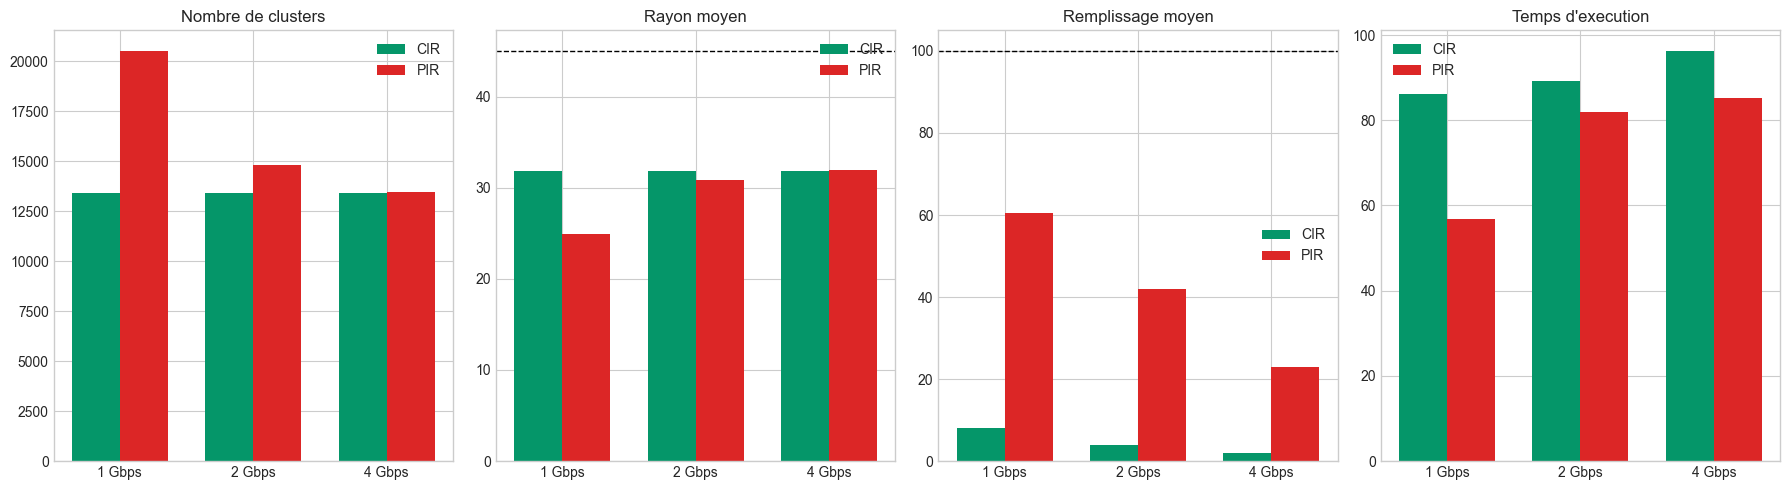

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
labels = [f'{int(c)} Gbps' for c in SCENARIOS_DEBIT]
x = np.arange(len(SCENARIOS_DEBIT))
width = 0.36

for offset, metric, color in [(-width/2, 'CIR', '#059669'), (width/2, 'PIR', '#dc2626')]:
    clusters = [resultats[metric][c]['nb_clusters'] for c in SCENARIOS_DEBIT]
    rayons = [resultats[metric][c]['rayons'].mean() for c in SCENARIOS_DEBIT]
    fills = [resultats[metric][c]['remplissage'].mean() for c in SCENARIOS_DEBIT]
    times = [resultats[metric][c]['duree'] for c in SCENARIOS_DEBIT]
    axes[0].bar(x + offset, clusters, width, label=metric, color=color)
    axes[1].bar(x + offset, rayons, width, label=metric, color=color)
    axes[2].bar(x + offset, fills, width, label=metric, color=color)
    axes[3].bar(x + offset, times, width, label=metric, color=color)

axes[0].set_title('Nombre de clusters')
axes[1].set_title('Rayon moyen')
axes[2].set_title('Remplissage moyen')
axes[3].set_title("Temps d'execution")
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.legend()
axes[1].axhline(RAYON_MAX_KM, color='black', linestyle='--', linewidth=1)
axes[2].axhline(100, color='black', linestyle='--', linewidth=1)

plt.tight_layout()
plt.savefig('comparaison_cir_pir.png', dpi=160, bbox_inches='tight')
plt.show()


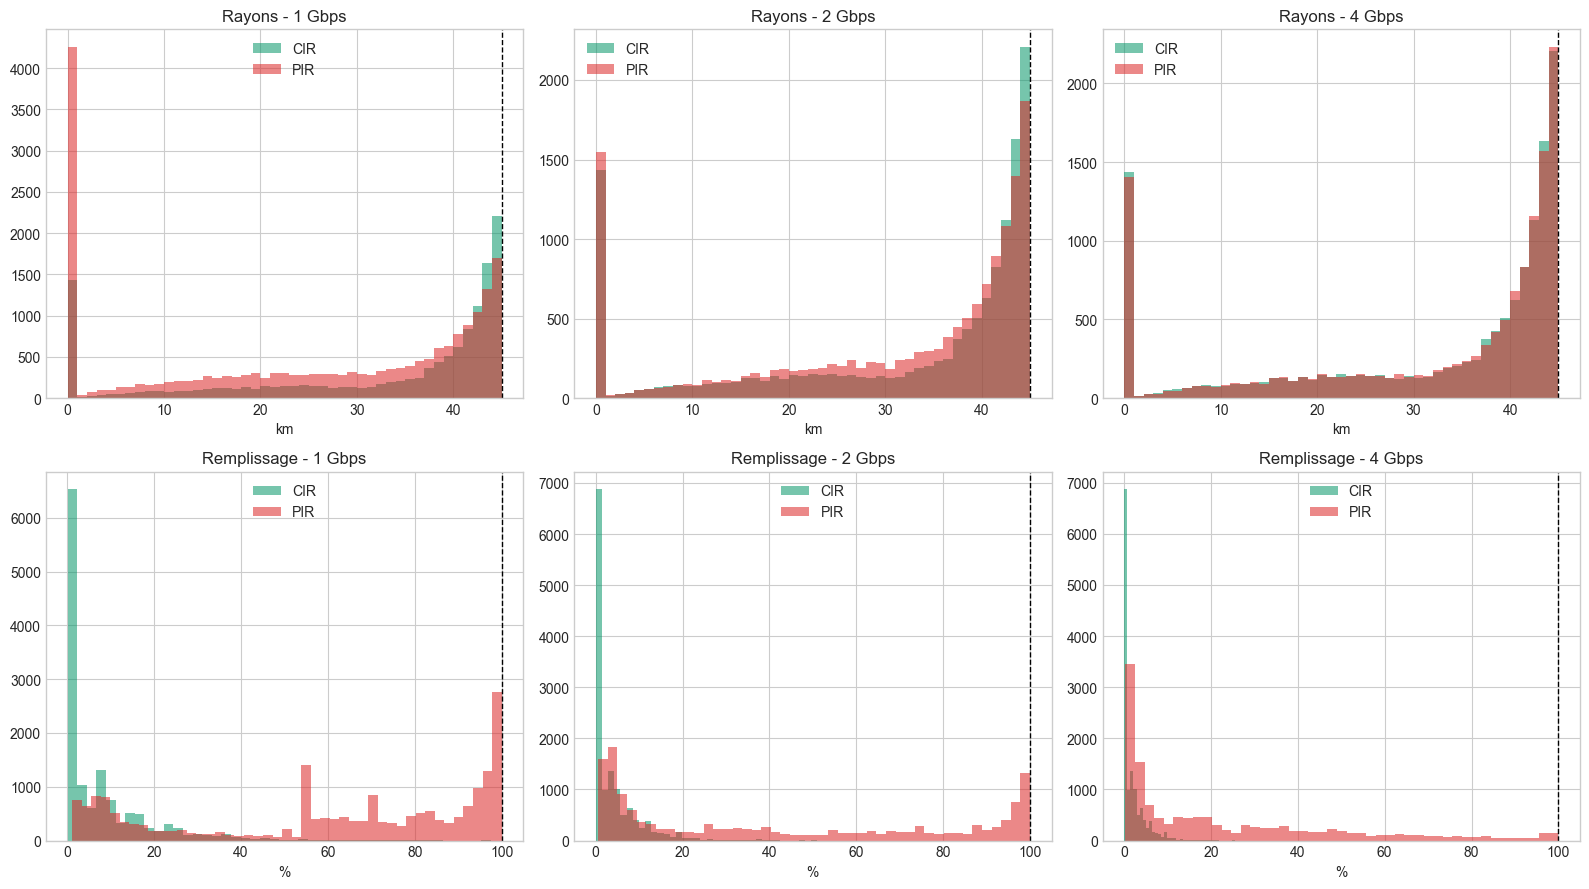

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
colors = {'CIR': '#059669', 'PIR': '#dc2626'}

for idx, capacity in enumerate(SCENARIOS_DEBIT):
    for metric in METRICS_TO_RUN:
        r = resultats[metric][capacity]
        axes[0, idx].hist(r['rayons'], bins=45, alpha=0.55, color=colors[metric], label=metric)
        axes[1, idx].hist(r['remplissage'], bins=45, alpha=0.55, color=colors[metric], label=metric)

    axes[0, idx].axvline(RAYON_MAX_KM, color='black', linestyle='--', linewidth=1)
    axes[0, idx].set_title(f'Rayons - {int(capacity)} Gbps')
    axes[0, idx].set_xlabel('km')
    axes[0, idx].legend()

    axes[1, idx].axvline(100, color='black', linestyle='--', linewidth=1)
    axes[1, idx].set_title(f'Remplissage - {int(capacity)} Gbps')
    axes[1, idx].set_xlabel('%')
    axes[1, idx].legend()

plt.tight_layout()
plt.savefig('stats_clusters_cir_pir.png', dpi=160, bbox_inches='tight')
plt.show()


## 11. Cartes statiques : terminaux vs centres de clusters

Ces figures comparent la densité géographique des terminaux avec celle des centres de clusters, sans afficher les cercles de couverture afin de garder une lecture claire à l'échelle mondiale. Les barres de couleur indiquent le nombre de points par case, avec une échelle logarithmique : plus la couleur est foncée, plus la zone contient de terminaux ou de centres.


Carte sauvegardee : carte_repartition_pir_1gbps.png


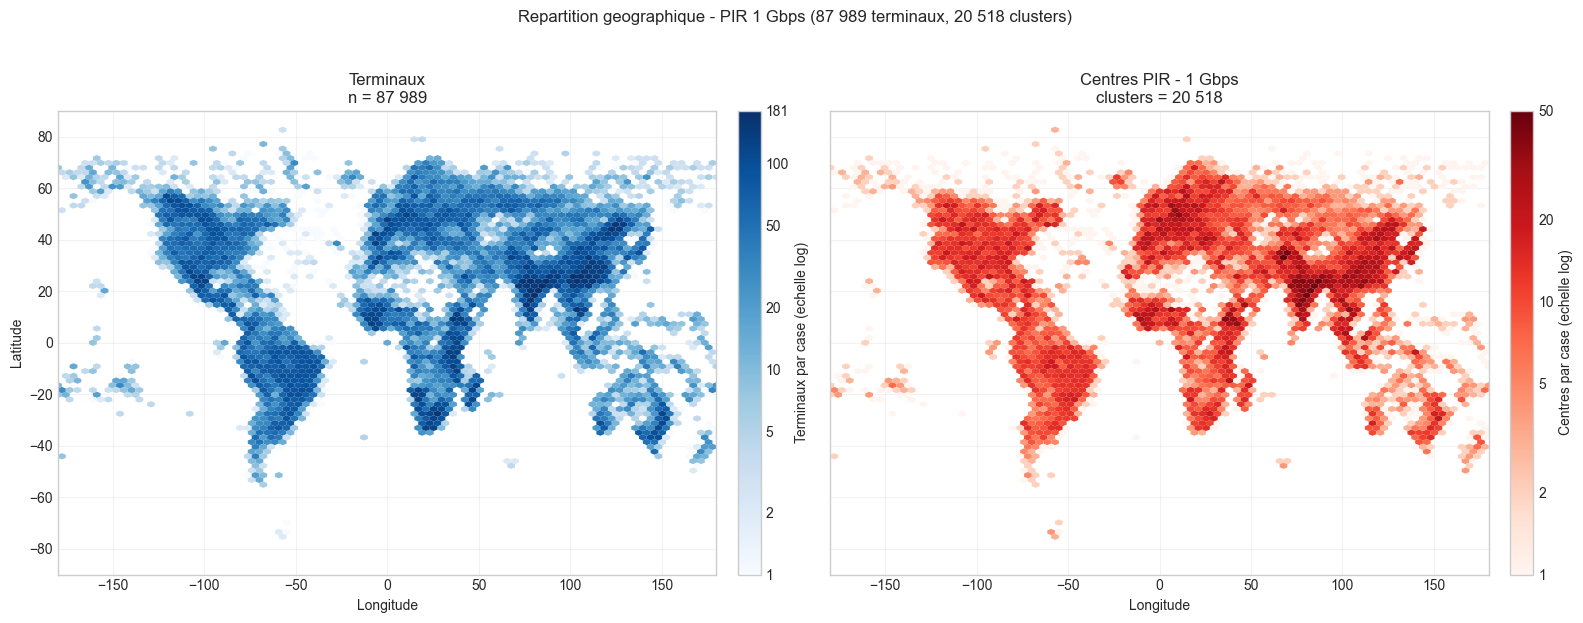

Carte sauvegardee : carte_repartition_pir_2gbps.png


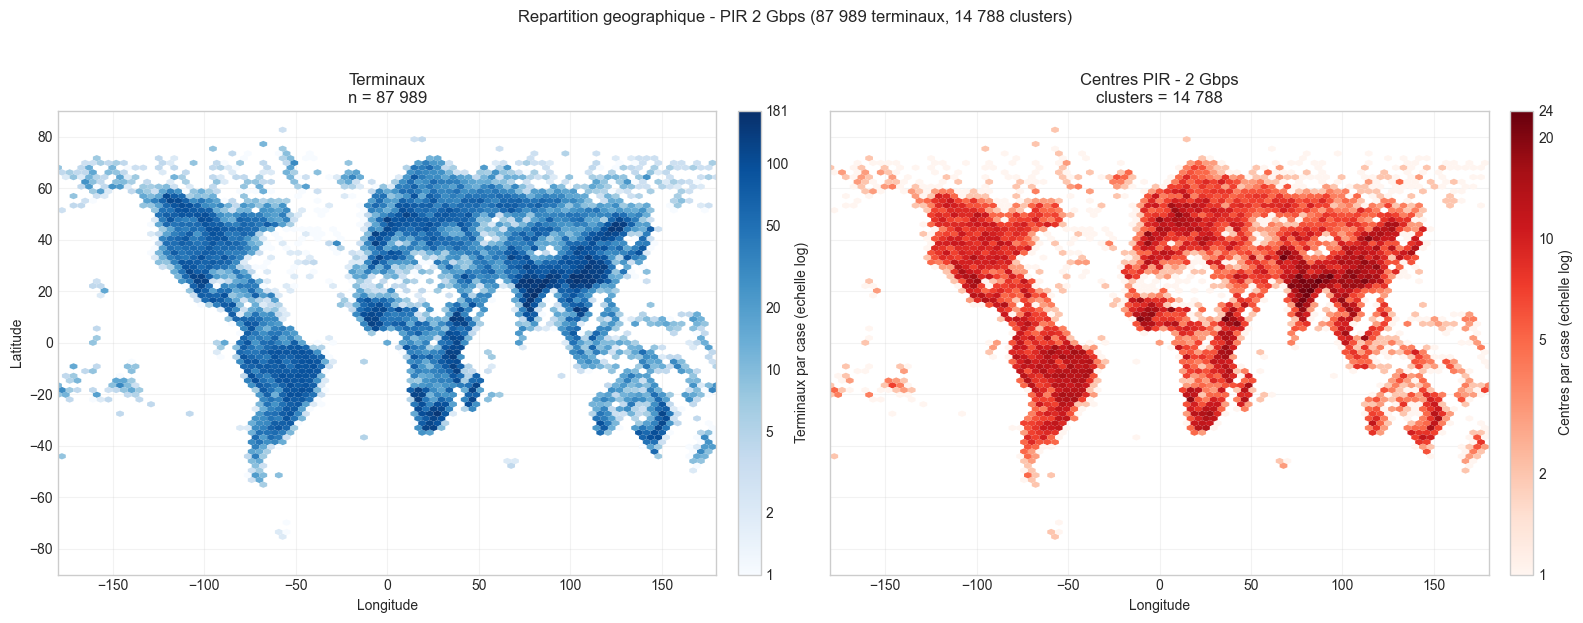

Carte sauvegardee : carte_repartition_pir_4gbps.png


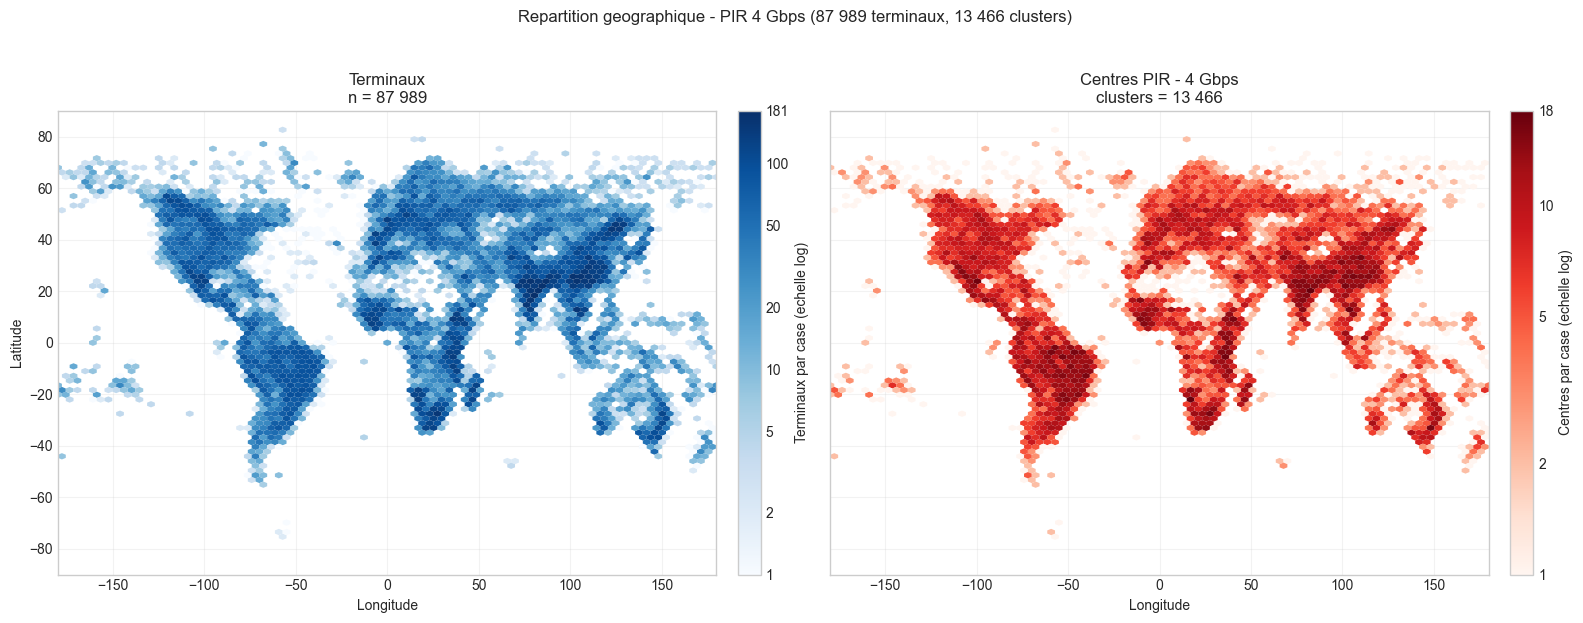

In [20]:
def format_int_fr(value):
    return f'{int(round(value)):,}'.replace(',', ' ')


def density_colorbar_ticks(max_count):
    """Construit des graduations lisibles pour une colorbar logarithmique."""
    max_count = max(1, int(np.ceil(max_count)))
    ticks = []
    power = 1
    while power <= max_count:
        for multiplier in (1, 2, 5):
            tick = multiplier * power
            if tick <= max_count:
                ticks.append(tick)
        power *= 10

    if max_count not in ticks:
        ticks.append(max_count)

    # Evite une colorbar surchargee tout en gardant les ordres utiles.
    if len(ticks) > 9:
        keep = np.linspace(0, len(ticks) - 1, 9, dtype=int)
        ticks = [ticks[i] for i in keep]

    return sorted(set(ticks))


def add_density_map(ax, lon, lat, cmap, title, colorbar_label, gridsize=85):
    """Affiche une carte de densite mondiale avec une echelle de comptage."""
    hb = ax.hexbin(
        lon,
        lat,
        gridsize=gridsize,
        extent=(-180, 180, -90, 90),
        mincnt=1,
        cmap=cmap,
        norm=LogNorm(vmin=1),
        linewidths=0,
    )
    ax.set_title(title)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xlabel('Longitude')
    ax.grid(True, alpha=0.25)
    counts = hb.get_array()
    max_count = float(np.nanmax(counts)) if len(counts) else 1.0
    ticks = density_colorbar_ticks(max_count)
    cbar = plt.colorbar(hb, ax=ax, fraction=0.046, pad=0.03, ticks=ticks)
    cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: format_int_fr(value)))
    cbar.ax.minorticks_off()
    cbar.set_label(colorbar_label)
    return hb


def plot_world_distribution(metric='PIR', capacity=1.0, save=True):
    """Compare la densite des terminaux et des centres de clusters sur une carte statique."""
    if metric not in resultats:
        raise ValueError(f'Metrique inconnue : {metric}')
    if capacity not in resultats[metric]:
        raise ValueError(f'Capacite inconnue pour {metric} : {capacity}')

    resultat = resultats[metric][capacity]
    centers = np.asarray(resultat['centers'], dtype=float)
    n_terminals = len(df_run)
    n_clusters = len(centers)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
    add_density_map(
        axes[0],
        df_run['LON'].to_numpy(float),
        df_run['LAT'].to_numpy(float),
        'Blues',
        f'Terminaux\nn = {format_int_fr(n_terminals)}',
        'Terminaux par case (echelle log)',
    )
    add_density_map(
        axes[1],
        centers[:, 1],
        centers[:, 0],
        'Reds',
        f'Centres {metric} - {int(capacity)} Gbps\nclusters = {format_int_fr(n_clusters)}',
        'Centres par case (echelle log)',
    )
    axes[0].set_ylabel('Latitude')
    plt.suptitle(
        f'Repartition geographique - {metric} {int(capacity)} Gbps '
        f'({format_int_fr(n_terminals)} terminaux, {format_int_fr(n_clusters)} clusters)',
        y=1.03,
    )
    plt.tight_layout()

    if save:
        filename = f'carte_repartition_{metric.lower()}_{int(capacity)}gbps.png'
        plt.savefig(filename, dpi=180, bbox_inches='tight')
        print(f'Carte sauvegardee : {filename}')
    plt.show()


def plot_world_distribution_all_capacities(metric='PIR', save=True):
    """Genere une carte terminaux vs centres pour chaque capacite."""
    for capacity in SCENARIOS_DEBIT:
        plot_world_distribution(metric=metric, capacity=capacity, save=save)


# Cartes representant le dimensionnement PIR pour chaque capacite.
plot_world_distribution_all_capacities(metric='PIR')


Carte sauvegardee : carte_repartition_cir_pir_1gbps.png


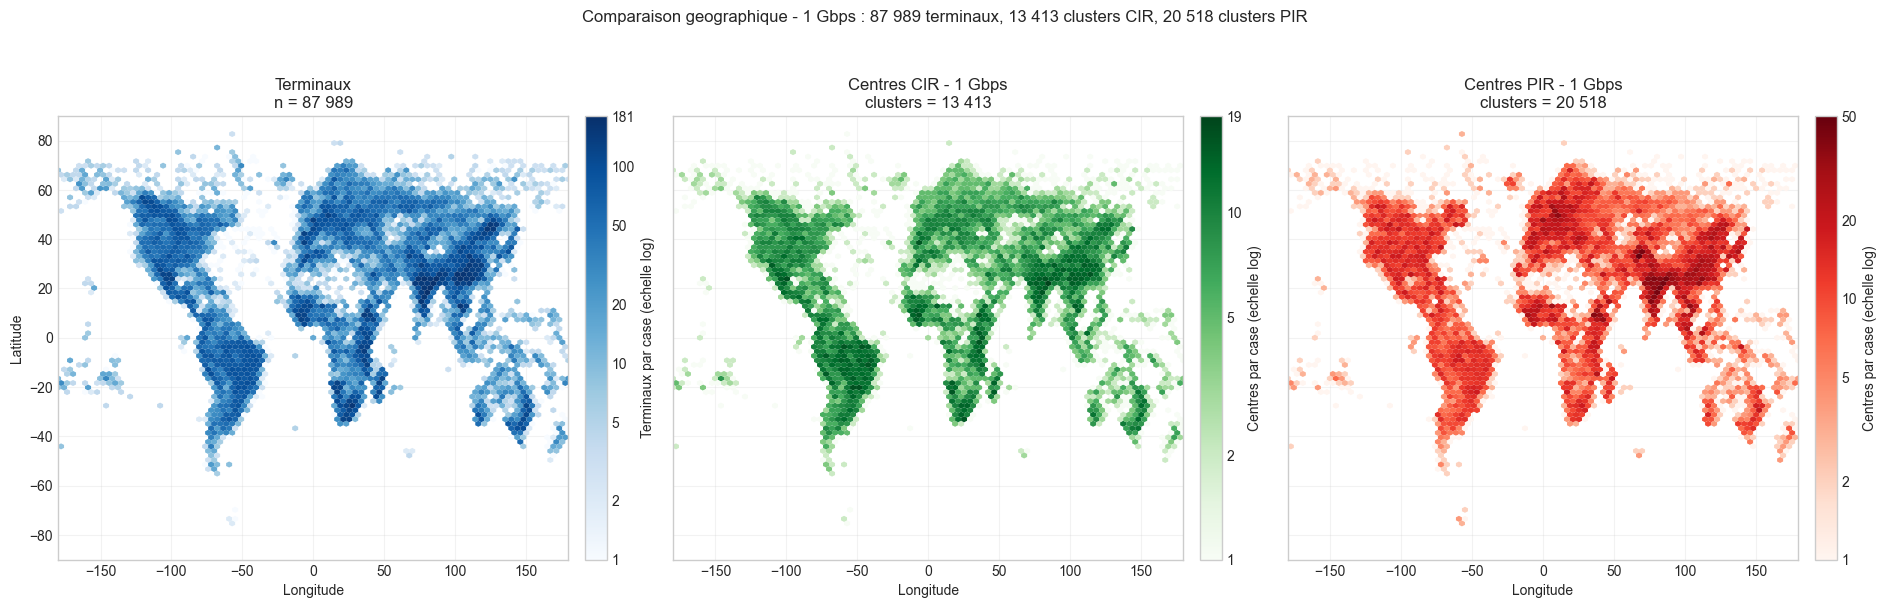

Carte sauvegardee : carte_repartition_cir_pir_2gbps.png


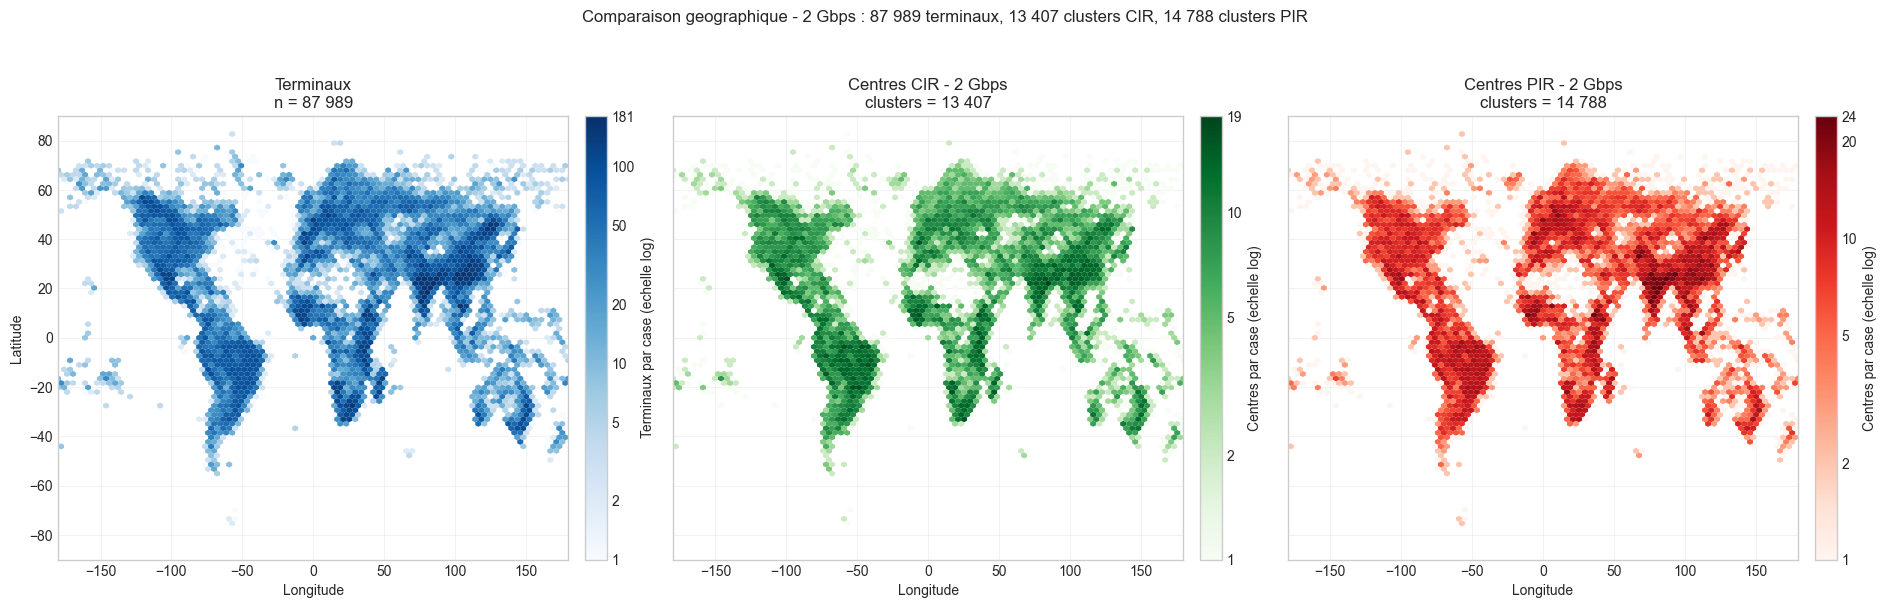

Carte sauvegardee : carte_repartition_cir_pir_4gbps.png


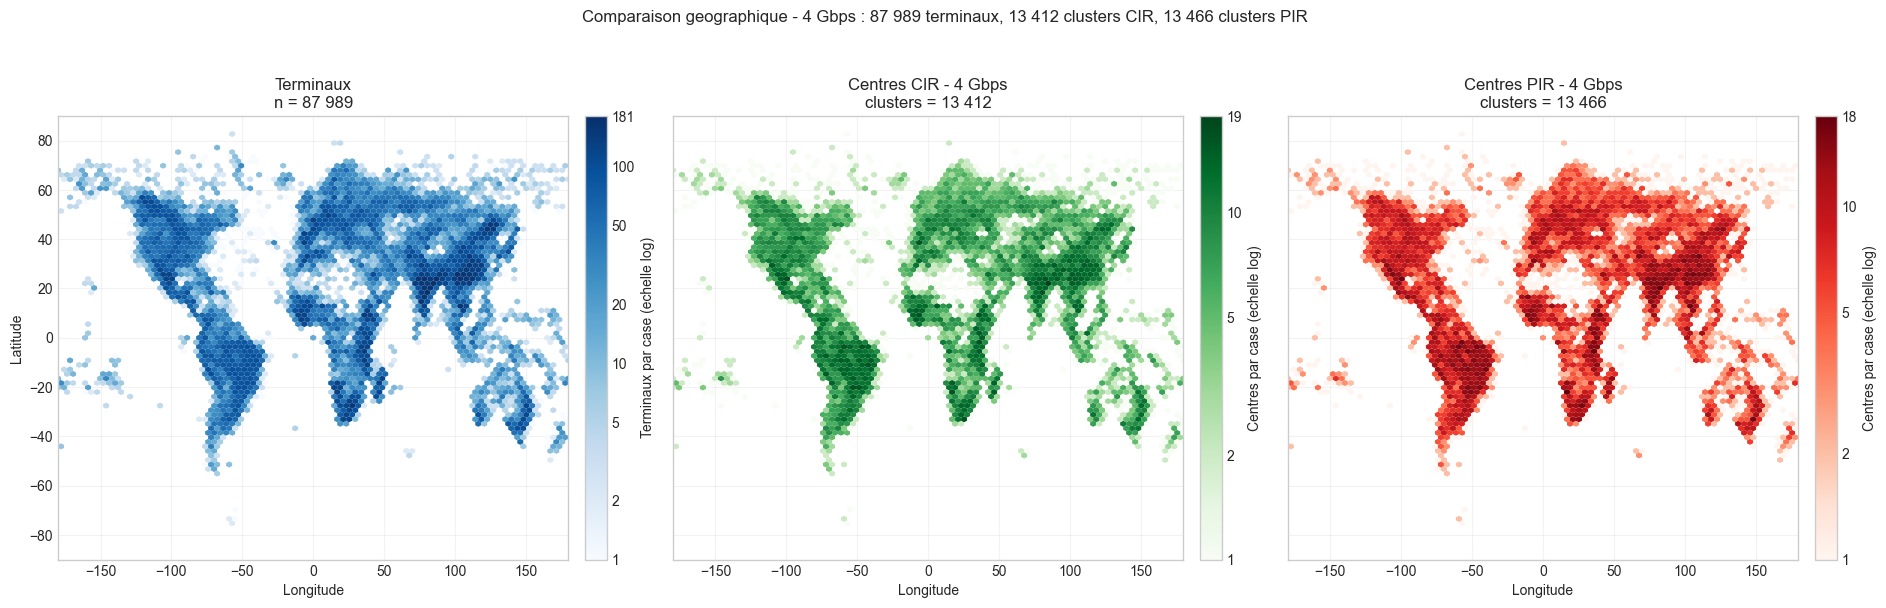

In [21]:
def plot_world_distribution_grid(capacity=2.0, save=True):
    """Compare terminaux, centres CIR et centres PIR pour une capacite donnee."""
    n_terminals = len(df_run)
    centers_cir = np.asarray(resultats['CIR'][capacity]['centers'], dtype=float)
    centers_pir = np.asarray(resultats['PIR'][capacity]['centers'], dtype=float)

    fig, axes = plt.subplots(1, 3, figsize=(19, 5.8), sharex=True, sharey=True)
    add_density_map(
        axes[0],
        df_run['LON'].to_numpy(float),
        df_run['LAT'].to_numpy(float),
        'Blues',
        f'Terminaux\nn = {format_int_fr(n_terminals)}',
        'Terminaux par case (echelle log)',
    )
    add_density_map(
        axes[1],
        centers_cir[:, 1],
        centers_cir[:, 0],
        'Greens',
        f'Centres CIR - {int(capacity)} Gbps\nclusters = {format_int_fr(len(centers_cir))}',
        'Centres par case (echelle log)',
    )
    add_density_map(
        axes[2],
        centers_pir[:, 1],
        centers_pir[:, 0],
        'Reds',
        f'Centres PIR - {int(capacity)} Gbps\nclusters = {format_int_fr(len(centers_pir))}',
        'Centres par case (echelle log)',
    )

    axes[0].set_ylabel('Latitude')
    plt.suptitle(
        f'Comparaison geographique - {int(capacity)} Gbps : '
        f'{format_int_fr(n_terminals)} terminaux, '
        f'{format_int_fr(len(centers_cir))} clusters CIR, '
        f'{format_int_fr(len(centers_pir))} clusters PIR',
        y=1.04,
    )
    plt.tight_layout()

    if save:
        filename = f'carte_repartition_cir_pir_{int(capacity)}gbps.png'
        plt.savefig(filename, dpi=180, bbox_inches='tight')
        print(f'Carte sauvegardee : {filename}')
    plt.show()


def plot_world_distribution_grid_all_capacities(save=True):
    """Genere la comparaison terminaux/CIR/PIR pour chaque capacite."""
    for capacity in SCENARIOS_DEBIT:
        plot_world_distribution_grid(capacity=capacity, save=save)


plot_world_distribution_grid_all_capacities()


## 12. Test de sensibilité au nombre de candidats `q`

`q` correspond au nombre maximal de candidats réellement validés à chaque étape du remplissage glouton. Le test ci-dessous permet de comparer plusieurs valeurs de `q` sur un échantillon, sans relancer automatiquement toute la campagne CIR/PIR.


In [ ]:
EXECUTER_TEST_SENSIBILITE_Q = True
Q_VALUES_TEST = [40, 80, 120]
Q_TEST_METRIC = 'PIR'
Q_TEST_CAPACITY = 2.0
Q_TEST_SAMPLE_SIZE = 15000


def tester_sensibilite_q(df_source, metric='PIR', capacity=2.0,
                         q_values=(40, 80, 120), sample_size=15000):
    df_metric = df_source.copy().reset_index(drop=True)
    df_metric['DEMAND_GBPS'] = df_metric[f'{metric}_GBPS']

    if sample_size is not None and sample_size < len(df_metric):
        df_metric = df_metric.sample(sample_size, random_state=42).reset_index(drop=True)

    rows = []
    for q in q_values:
        resultat_q = capacitated_p_center(
            df_metric,
            capacity,
            metric_name=f'{metric} q={q}',
            verbose=False,
            max_candidates_validation=q,
        )
        rows.append({
            'Demande': metric,
            'Capacite (Gbps)': int(capacity),
            'Taille echantillon': len(df_metric),
            'q': q,
            'Nb clusters': resultat_q['nb_clusters'],
            'Invalides': resultat_q['nb_invalides'],
            'Rayon moyen (km)': round(float(resultat_q['rayons'].mean()), 2),
            'Remplissage moyen (%)': round(float(resultat_q['remplissage'].mean()), 1),
            'Temps (s)': round(float(resultat_q['duree']), 1),
        })
    return pd.DataFrame(rows)


if EXECUTER_TEST_SENSIBILITE_Q:
    df_sensibilite_q = tester_sensibilite_q(
        df_run,
        metric=Q_TEST_METRIC,
        capacity=Q_TEST_CAPACITY,
        q_values=Q_VALUES_TEST,
        sample_size=Q_TEST_SAMPLE_SIZE,
    )
    afficher_tableau(df_sensibilite_q)
else:
    print('Test non execute. Passer EXECUTER_TEST_SENSIBILITE_Q a True pour lancer la comparaison de q.')


Test non execute. Passer EXECUTER_TEST_SENSIBILITE_Q a True pour lancer la comparaison de q.


## 13. Points à retenir

- Le problème est traité comme un p-center capacitaire : rayon maximal `45 km` et capacité `1/2/4 Gbps`.
- Les solutions CIR et PIR sont calculées séparément avec le même algorithme.
- Les terminaux virtuels rendent faisables les cas où une demande individuelle dépasse la capacité.
- Les clusters peuvent se superposer partiellement ou totalement ; chaque terminal virtuel est affecté une seule fois.
- Les vérifications automatiques contrôlent couverture, conservation du débit, rayon, capacité et bornes inférieures.
- La comparaison CIR/PIR montre l'écart entre un dimensionnement sur débit garanti et un dimensionnement sur débit maximal.
